# 059 — svc linear

SVC linear versus configuração LinearSVC do 037 (C=0,01, balanced).

**Estado: executado pelo runner; outputs guardados.**

Seleção dentro do treino de desenvolvimento (8.769 linhas), com os mesmos três folds. Validação fixa: 2.193 linhas, já observada anteriormente. Pré-processamento ajustado dentro de cada treino. Sem submissão automática.

059 resultado completo reutilizado após verificar o contexto.
Estado: procedimento concluído; resultados guardados com contexto verificado.
Versões: {'numpy': '2.5.3', 'pandas': '3.0.6', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'torch': '2.15.0', 'xgboost': '3.4.1', 'lightgbm': '4.7.0'}
Duração original (s): 589.2981284169946
Notas: Seleção só pela CV no treino. A validação fixa é desenvolvimento e não escolhe parâmetros. Configurações de experiências anteriores já foram selecionadas nestas mesmas linhas; CV pós-seleção não é avaliação independente.
Selecionado: svc_linear
Configuração: {'family': 'svc', 'kernel': 'linear', 'C': 0.01, 'gamma': 'scale', 'degree': 3, 'coef0': 0.0, 'class_weight': 'balanced', 'strategy': 'ovo', 'svd': 0}
Diferenças emparelhadas: {'differences': [0.026065884634710546, 0.01622275609120799, 0.013415458396061064], 'mean': 0.018568033040659866, 'std': 0.006643309715954882}
Escalões: controlo
Diagnósticos de ajuste: {'seconds': 4.226523499994073, 'warnings':

,configuração,Macro F1 CV,DP,folds
0,controlo_037,0.416405,0.006600,"[0.4088548930305602, 0.419282167665054, 0.4210..."
1,svc_linear,0.434973,0.000508,"[0.43492077766527076, 0.435504923756262, 0.434..."


,modelo,parcela,Macro F1,accuracy
0,controlo,train,0.733732,0.717300
1,controlo,validation,0.395200,0.399453
2,selecionado,train,0.666314,0.647622
3,selecionado,validation,0.428511,0.430917


,classe,precision,recall,F1,support
0,0,0.674419,0.707317,0.690476,41
1,1,0.279070,0.352941,0.311688,34
2,2,0.481013,0.475000,0.477987,80
3,3,0.309278,0.400000,0.348837,75
4,4,0.203252,0.277778,0.234742,90
5,5,0.256944,0.286822,0.271062,129
6,6,0.350000,0.203488,0.257353,172
7,7,0.388060,0.300578,0.338762,173
8,8,0.549296,0.646409,0.593909,181
9,9,0.544248,0.605911,0.573427,203


,classe,precision,recall,F1,support
0,0,0.761905,0.780488,0.771084,41
1,1,0.339286,0.558824,0.422222,34
2,2,0.517241,0.375000,0.434783,80
3,3,0.280899,0.333333,0.304878,75
4,4,0.195489,0.288889,0.233184,90
5,5,0.293706,0.325581,0.308824,129
6,6,0.401460,0.319767,0.355987,172
7,7,0.371622,0.317919,0.342679,173
8,8,0.609467,0.569061,0.588571,181
9,9,0.630332,0.655172,0.642512,203


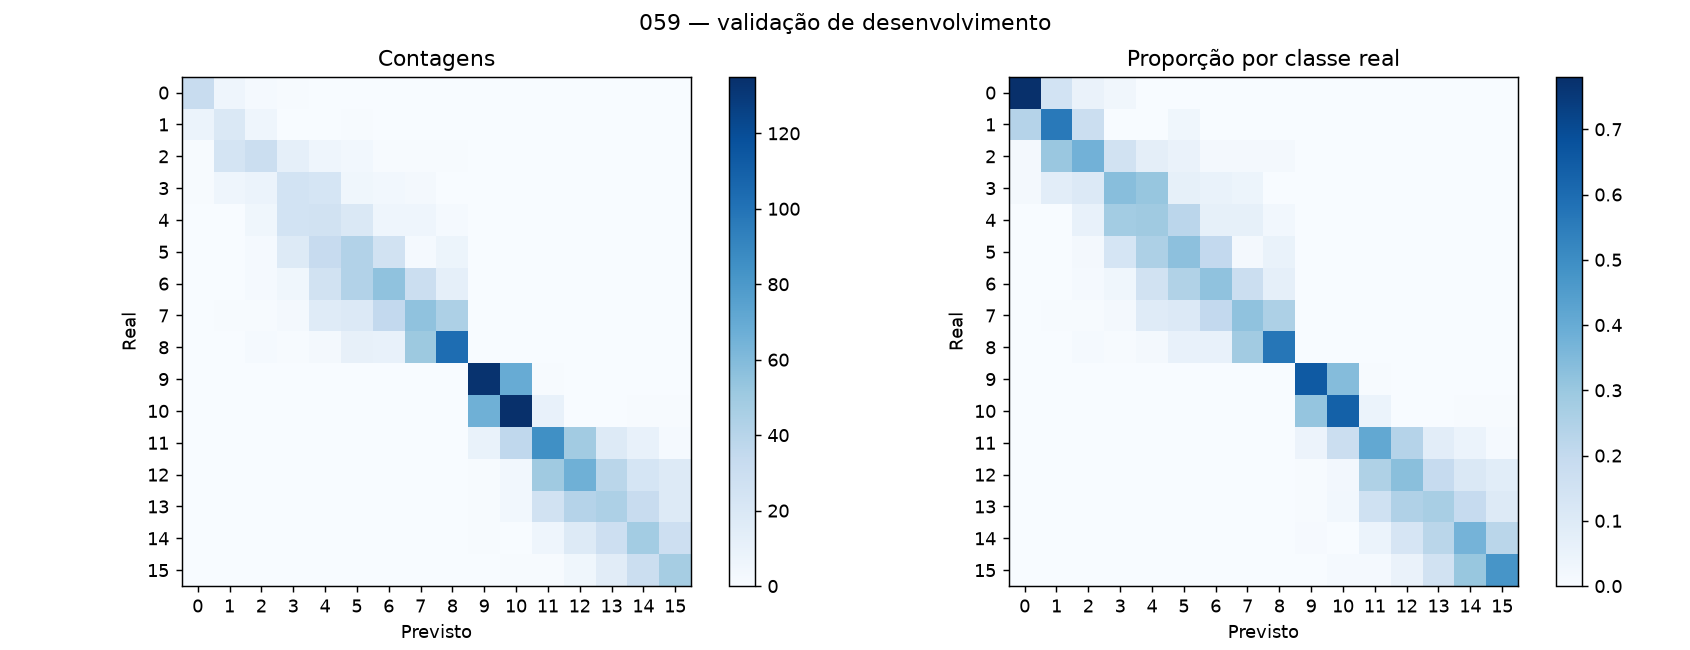

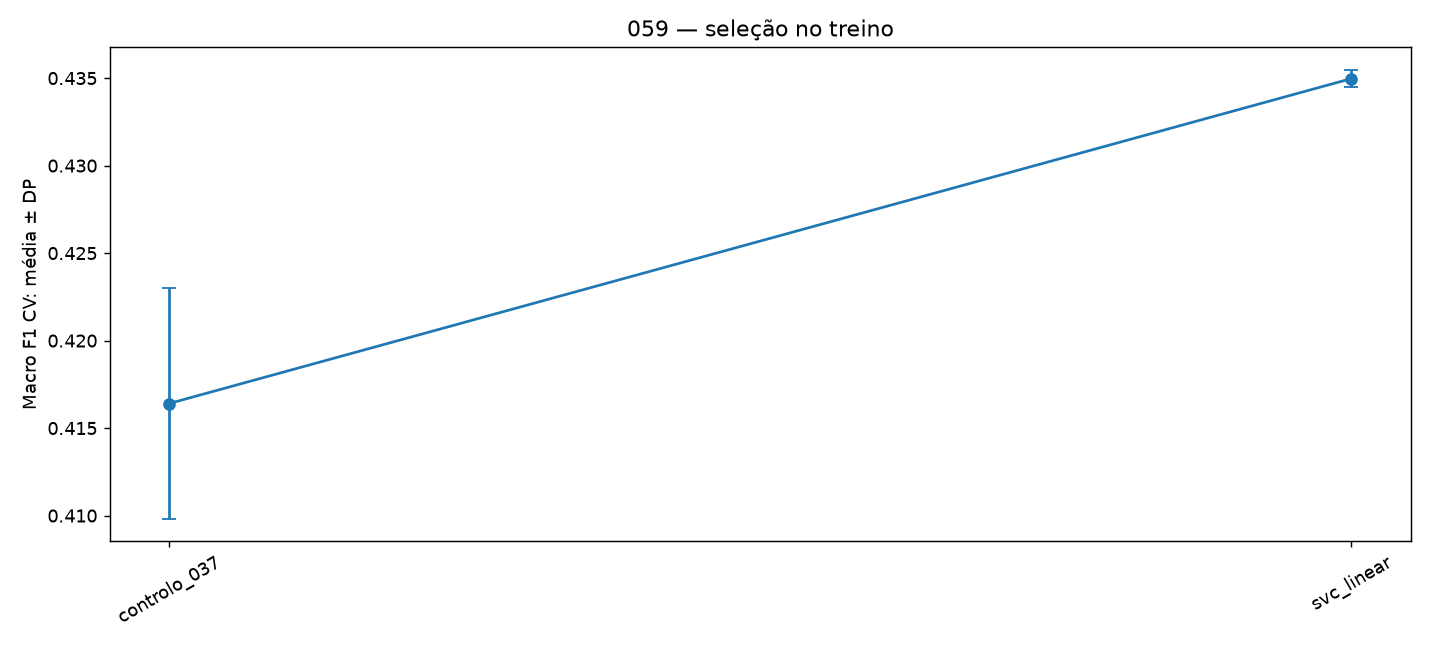

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image
root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p/'src/experiments_059_075.py').is_file())
sys.path.insert(0, str(root))
from src.experiments_059_075 import run_experiment
result = run_experiment('059')
print('Estado: procedimento concluído; resultados guardados com contexto verificado.')
print('Versões:', result['context']['base']['versions'])
print('Duração original (s):', result['seconds'])
print('Notas:', result.get('note', ''))
if result.get('candidates'):
    display(pd.DataFrame([{'configuração':r['label'],'Macro F1 CV':r['mean'],'DP':r['std'],'folds':r.get('folds',r.get('scores'))} for r in result['candidates']]))
if result.get('selected'):
    print('Selecionado:', result['selected']['label'])
    print('Configuração:', result['selected']['spec'])
if result.get('paired_cv'):
    print('Diferenças emparelhadas:', result['paired_cv'])
if result.get('fixed'):
    display(pd.DataFrame([{'modelo':name,'parcela':part,'Macro F1':groups[part]['macro_f1'],'accuracy':groups[part]['accuracy']} for name,groups in result['fixed'].items() for part in ['train','validation']]))
    for name, groups in result['fixed'].items():
        print('Escalões:', name)
        display(pd.DataFrame(groups['validation']['per_class']))
        print('Diagnósticos de ajuste:', groups.get('diagnostics'))
        print('MAE em códigos de escalão (não anos):', groups.get('mae_in_class_codes'))
        if 'log_loss' in groups: print('Log loss:',groups['log_loss'])
if result.get('metrics_oof'):
    print('Métricas OOF de desenvolvimento:', result['metrics_oof']['macro_f1'], result['metrics_oof']['accuracy'])
    display(pd.DataFrame(result['metrics_oof']['per_class']))
if 'selected_cases' in result:
    print('Perfis sinalizados:', result['flagged'], '/', result['total'])
    display(pd.DataFrame(result['selected_cases']))
    display(pd.DataFrame(result['by_class']))
if 'categorical_profiles' in result:
    table = pd.DataFrame(result['categorical_profiles'])
    display(table[table.variable.isin(['HATLEVEL','MAINSTAT','HHINCOME','HS1','HS2'])])
    display(pd.DataFrame(result['numeric_profiles']))
    display(pd.DataFrame(result['chronic_diseases']))
for file in sorted((root/'reports').glob('experiencia_059_*.png')):
    display(Image(filename=str(file)))
print('CSV Kaggle:', result.get('submission'))
print('Pontuação Kaggle:', result['kaggle_score'])


## Conclusões locais

- Selecionado internamente: `svc_linear`.
- Macro F1 desenvolvimento: **0.4285**; accuracy: **0.4309**.
- Diferença face ao controlo contemporâneo: **+0.0333**.
- Diferença média nos mesmos folds: **+0.0186**, DP **0.0066**.
- CSV: `submissions/submission_059_svc_linear.csv`. Motivo se não criado: —.

Seleção só pela CV no treino. A validação fixa é desenvolvimento e não escolhe parâmetros. Configurações de experiências anteriores já foram selecionadas nestas mesmas linhas; CV pós-seleção não é avaliação independente.

**Decisão:** preencher depois da revisão; não inferir melhoria pública de uma pequena diferença local.

## Registo manual

- Data:
- CSV submetido (se aplicável):
- Nota Kaggle:
- Conclusão:
- Melhorias a experimentar:

Esta célula e quaisquer notas pessoais não são substituídas pelo script.